# Keras 소개

- Keras 3의 도입
  - 과거에는 텐서플로우 내부에 포함된 tf.keras가 표준처럼 쓰였지만, 최신 Keras 3부터는 텐서플로우뿐만 아니라 PyTorch와 JAX까지 백엔드로 선택할 수 있는 멀티 프레임워크(Multi-framework) 라이브러리로 완전히 독립했다.
  - 이에 따라 공식 권장 사항도 import keras를 직접 사용하는 것으로 바뀌었다.
- 주요 특징
  - 백엔드 유연성: 코드를 수정하지 않고도 KERAS_BACKEND 환경 변수 설정만으로 텐서플로우, 파이토치, 잭스 중 원하는 엔진을 골라서 실행할 수 있다.
  - 성능 및 호환성: Keras 3의 keras.ops API 등을 활용하면 각 백엔드에 최적화된 연산을 효율적으로 수행할 수 있다. (keras 2 에서는 keras.backend의 축약어로 K 가 쓰였음)

## 1. 가장 표준적인 흐름: Sequential + compile/fit/evaluate
- compile() + fit()만으로 끝나는 가장 기본적인 지도학습

In [ ]:
import keras
from keras import layers
import matplotlib.pyplot as plt

In [ ]:

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, epochs=5, validation_split=0.2)
model.evaluate(x_test, y_test)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8176 - loss: 0.5191 - val_accuracy: 0.8367 - val_loss: 0.4558
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8604 - loss: 0.3852 - val_accuracy: 0.8578 - val_loss: 0.3799
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8740 - loss: 0.3445 - val_accuracy: 0.8717 - val_loss: 0.3579
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8832 - loss: 0.3213 - val_accuracy: 0.8710 - val_loss: 0.3548
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8884 - loss: 0.3027 - val_accuracy: 0.8851 - val_loss: 0.3273
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8746 - loss: 0.3558


[0.3558022677898407, 0.8745999932289124]

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,312 (1.16 MB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,542 (795.09 KB)

In [ ]:
model.input_shape, model.output_shape

((None, 28, 28), (None, 10))

In [ ]:
784*128 + 128, 128*10 + 10

(100480, 1290)

In [ ]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

## 2. 과적합 다루기: Dropout + EarlyStopping
-  epochs=50을 줘도 val_loss가 3 epoch 연속 안 좋아지면 알아서 멈추고, 가장 좋았던 가중치로 복원한다.
- callbacks라는 개념(학습 중간에 개입하는 훅)을 처음 소개.
- history.history로 train/val loss 곡선을 그려서 "Dropout 있을 때/없을 때"를 비교해 보기 바람.

In [ ]:
import keras
from keras import layers

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

In [ ]:
y_train[:5]  # one-hot encoding 이 아닐 경우는 loss = sparse_categorical_crossentropy 사용
             # one-hot encoding 인 경우는 loss = categorical_crossentropy 사용

array([9, 0, 0, 3, 0], dtype=uint8)

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),          # 학습 때만 일부 뉴런을 끔
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history = model.fit(
    x_train, y_train, epochs=50, validation_split=0.2,
    callbacks=[early_stop],
)

Epoch 1/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8039 - loss: 0.5479 - val_accuracy: 0.8519 - val_loss: 0.4145
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8495 - loss: 0.4133 - val_accuracy: 0.8558 - val_loss: 0.3902
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8612 - loss: 0.3793 - val_accuracy: 0.8727 - val_loss: 0.3492
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8673 - loss: 0.3569 - val_accuracy: 0.8469 - val_loss: 0.4099
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8740 - loss: 0.3407 - val_accuracy: 0.8717 - val_loss: 0.3564
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8794 - loss: 0.3268 - val_accuracy: 0.8820 - val_loss: 0.3273
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8820 - loss: 0.3148 - val_accuracy: 0.8848 - val_loss: 0.3269
Epoch 8/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8843 - loss: 0.3085 - 

In [ ]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

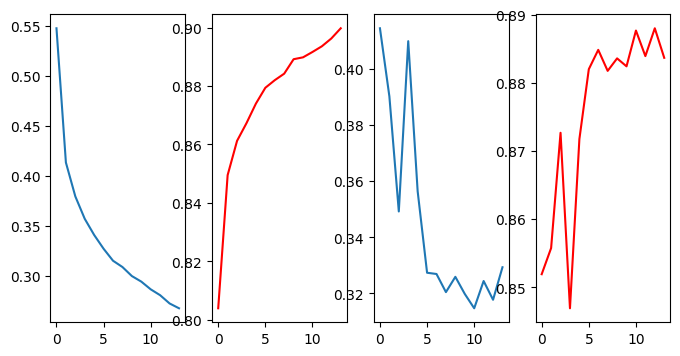

In [ ]:
plt.figure(figsize=(8,4))
plt.subplot(1,4,1)
plt.plot(history.history['loss'], label='loss')
plt.subplot(1,4,2)
plt.plot(history.history['accuracy'], label='accuracy', c='r')
plt.subplot(1,4,3)
plt.plot(history.history['val_loss'], label='loss')
plt.subplot(1,4,4)
plt.plot(history.history['val_accuracy'], label='accuracy', c='r')

plt.show()

## 3. Functional API: Sequential이 못 하는 구조
- 입력이 2개, 혹은 중간에 여러 갈래로 갈라졌다 합쳐지는 구조는 Sequential(한 줄로만 쌓는 구조)로는 표현이 안 된다.
- "레이어들이 선형으로만 이어지지 않을 때 Functional API가 필요해진다.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 28, 28)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 784)       │          0 │ image[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │     50,240 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meta (InputLayer)   │ (None, 5)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 69)        │          0 │ dense_2[0][0],    │
│ (Concatenate)       │                   │            │ meta[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      2,240 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 10)        │        330 │ dense_3[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 52,810 (206.29 KB)

 Trainable params: 52,810 (206.29 KB)

 Non-trainable params: 0 (0.00 B)

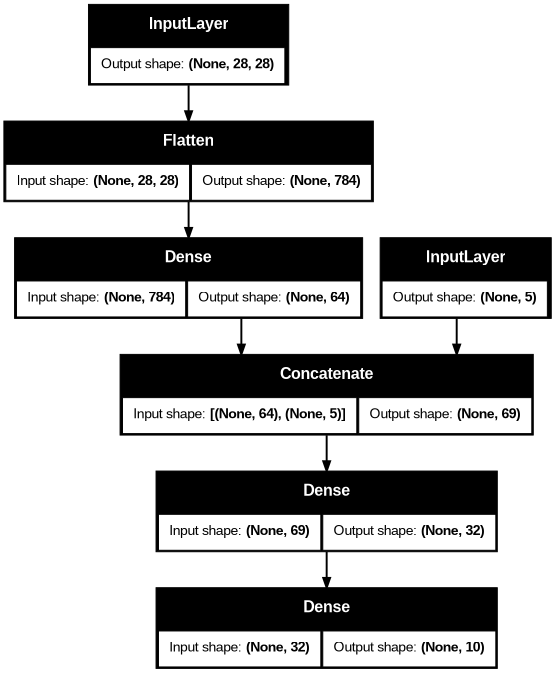

In [ ]:
# 두 종류의 입력(예: 이미지 + 수치형 메타데이터)을 합치는 구조
image_input = layers.Input(shape=(28, 28), name="image")
meta_input = layers.Input(shape=(5,), name="meta")

x = layers.Flatten()(image_input)
x = layers.Dense(64, activation="relu")(x)

merged = layers.Concatenate()([x, meta_input])
merged = layers.Dense(32, activation="relu")(merged)
output = layers.Dense(10, activation="softmax")(merged)

model = keras.Model(inputs=[image_input, meta_input], outputs=output)
model.summary()

keras.utils.plot_model(model, "my_model.png", show_shapes=True, dpi=70)

## 4. Custom Layer: Dense를 직접 재구현하기

- keras.layer.Dense() 층이 하는 일 중 가장 핵심적인 계산 부분만 그대로(정확하게) 구현한 예제. (Dense 전체 기능을 다 만든 게 아님)
- add_weight(): keras.layers.Layer가 기본으로 제공하는 메서드로,"이 레이어가 학습 중 계속 갖고 있을 숫자(가중치)를 하나 만들어달라"고 요청하는 함수.
- build(self, input_shape): 가중치를 실제로 만드는 곳. 딱 한 번, 첫 입력이 들어오는 순간에 자동으로 호출된다. (즉, build()는 실제 입력이 들어와서 input_shape을 볼 수 있게 된 그 순간 호출되므로, 그때 비로소 W, b를 만들 수 있다.)
- call(self, inputs): 입력이 들어왔을 때 실제로 어떤 계산을 할지"를 적는 곳. build()가 만들어둔 W, b를 가지고 매번(매 배치, 매 호출마다) 실행된다.

In [ ]:
class MyDense(layers.Layer):
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.units = units   # output_dim

    def build(self, input_shape):
        input_dim = input_shape[-1]
        self.W = self.add_weight(
            shape=(input_dim, self.units),   # 만들 텐서의 모양
            initializer="glorot_uniform",    # 처음
            trainable=True,                  # 학습(gradient 업데이트) 대상인지
            name="W",                        # 이름 (저장/디버깅용, 선택)
        )
        self.b = self.add_weight(
            shape=(self.units,),
            initializer="zeros",
            trainable=True,
            name="b",
        )

    def call(self, inputs):
        return keras.ops.matmul(inputs, self.W) + self.b


# 사용 예 — keras.layers.Dense와 완전히 똑같이 동작함
model = keras.Sequential([
    layers.Input(shape=(3,)),
    MyDense(2),   # keras.layers.Dense(2)와 결과가 동일
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ my_dense (MyDense)              │ (None, 2)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8 (32.00 B)

 Trainable params: 8 (32.00 B)

 Non-trainable params: 0 (0.00 B)

## 5. Custom Model: Gradient Clipping 하나만 추가
- call(): train_step()이 실행될 때마다 그 안에서 호출된다.
- train_step(): model.fit(...)을 부르면, 그 내부에서 매 배치마다 우리가 정의한 train_step()이 자동으로 호출된다.
- 흐름도
```
- fit() 호출
 └─ (배치마다 반복)
     └─ train_step() 실행
         └─ self(x, training=True) 실행 (모델 자체를 함수처럼 수행)
             └─ __call__() 실행
                 ├─ (최초 1회만) build() 실행 → 가중치 생성
                 └─ (매번) call() 실행 → 실제 순전파 계산
```

In [ ]:
import keras
from keras import layers
import tensorflow as tf

# ==========================================
# 1. 데이터 준비
# ==========================================
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

# ==========================================
# 2. Custom Model — __init__ / call() / train_step() 모두 명시
# ==========================================
class ClippedModel(keras.Model):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        # 이 모델이 갖고 있는 부품(하위 레이어)들을 여기서 선언
        self.flatten = layers.Flatten()
        self.dense1 = layers.Dense(128, activation="relu")
        self.dense2 = layers.Dense(10, activation="softmax")

    def call(self, inputs):
        # 부품들을 어떤 순서로 연결해서 계산할지
        x = self.flatten(inputs)
        x = self.dense1(x)
        return self.dense2(x)

    def train_step(self, data):
        x, y = data

        with tf.GradientTape() as tape:
            y_pred = self(x, training=True)         # model(x) 호출: 여기서 __call__() → call() 실행됨
            loss = self.compute_loss(y=y, y_pred=y_pred)        # compile(loss=...)로 지정한 손실 그대로 사용

        grads = tape.gradient(loss, self.trainable_weights)
        grads = [keras.ops.clip(g, -1.0, 1.0) for g in grads]   # <- 유일한 커스텀 로직
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        for metric in self.metrics:
            if metric.name == "loss":
                metric.update_state(loss)           # loss 트래커는 손실값 하나만
            else:
                metric.update_state(y, y_pred)      # 나머지(accuracy 등)는 (y, y_pred)

        return {m.name: m.result() for m in self.metrics}

# ==========================================
# 3. 모델 생성 및 컴파일
# ==========================================
model = ClippedModel(name="clipped_model")
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# ==========================================
# 4. 학습 & 평가
# ==========================================
model.build(input_shape=(None, 28, 28))   # subclass 모델이라 build를 미리 해두면 summary()도 바로 가능
model.summary()

history = model.fit(x_train, y_train, epochs=5, validation_split=0.2)
model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'clipped_model', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "clipped_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8165 - loss: 0.5228 - val_accuracy: 0.8501 - val_loss: 0.4302
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8576 - loss: 0.3931 - val_accuracy: 0.8584 - val_loss: 0.4038
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8733 - loss: 0.3488 - val_accuracy: 0.8742 - val_loss: 0.3540
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8838 - loss: 0.3210 - val_accuracy: 0.8737 - val_loss: 0.3548
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8878 - loss: 0.3043 - val_accuracy: 0.8784 - val_loss: 0.3339
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8738 - loss: 0.3550


[0.3550085425376892, 0.8737999796867371]

### Custom Model 생성 시 내부 실행 과정
- Keras에서 keras.Model을 상속받아 커스텀 모델을 만들 때, 데이터가 입력되어 출력과 손실이 계산되는 전체적인 내부 실행 흐름은 다음과 같다.

1. \_\_init__ (초기화 단계)
    - 모델 객체가 생성될 때 호출된다.
    - 사용할 층(Layer)이나 컴포넌트(Dense, Conv2D 등)를 정의하고 인스턴스화한다.
    - 가중치(Weights)나 학습 가능한 변수들은 이 단계에서 생성되거나 첫 데이터가 들어올 때(build 단계) 생성된다.

2. build (가중치 빌드 단계)
    - 모델에 최초로 데이터가 입력되어 셰이프(Shape)가 확정될 때 호출된다.
    - __init__에서 크기가 지정되지 않았던 가중치(Weights)들의 실제 크기를 결정하고 메모리를 할당한다. (필요한 경우 직접 오버라이드하여 구현한다.)
    - 사용자가 build 메서드를 따로 정의하지 않아도, 최초로 데이터가 입력되어 순전파(call)가 실행되는 시점에 입력 텐서의 형태(Shape)를 바탕으로 내부적으로 가중치를 자동으로 생성(Build)한다.

3. call (순전파, Forward Pass)
    - 입력 데이터 inputs가 모델에 들어왔을 때 실제로 연산이 수행되는 핵심 순서이다.
    - 정의된 층들을 차례대로 통과시키며 출력을 계산한다.
    - training=True/False 인자를 받아 드롭아웃(Dropout)이나 배치 정규화(Batch Normalization)처럼 학습과 추론 시 다르게 동작해야 하는 연산을 분기 처리할 수 있다.

4. train_step (학습 스텝, model.fit() 호출 시)
    - model.fit()을 실행하면 내부적으로 매 배치(Batch)마다 train_step 메서드가 반복 호출된다.
    - train_step의 내부 동작은 다음과 같다.
      1. 순전파 수행: call() 메서드를 호출하여 예측값(y_pred)을 얻는다.
      2. 손실 계산: 지정된 loss 함수를 사용해 예측값(y_pred)과 실제값(y_true) 간의 손실(Loss)을 계산한다.
      3. 기울기(Gradient) 계산: tf.GradientTape(또는 백엔드에 해당하는 자동 미분 도구)를 통해 손실에 대한 모델 가중치의 기울기를 구한다.
      4. 가중치 업데이트: 최적화 알고리즘(Optimizer)을 이용해 계산된 기울기를 바탕으로 가중치를 갱신한다.
      5. 메트릭 업데이트: metrics로 지정된 지표(Accuracy 등)를 업데이트하고 반환한다.

5. test_step (model.evaluate() 호출 시)
    - 검증(Validation)이나 평가(Evaluation)를 수행할 때 호출된다.
    - train_step과 유사하지만, 기울기를 계산하거나 가중치를 업데이트하는 과정(GradientTape 및 Optimizer 적용)이 생략되고 순전파와 손실·메트릭 계산만 수행된다.
